# Isolation Forest y One-Class SVM RBF — AIOps

Implementación de la issue #14 sobre el dataset sintético docente: 300 ventanas de un minuto de checkout, semilla 42. El notebook original se conserva en [practico_detectores_aiops.ipynb](practico_detectores_aiops.ipynb).

**Aceptación académica pendiente de Q03.** Este material no representa métricas medidas en PharmaGo/Kubernetes. K-sigma/MAD y las preguntas del práctico completo siguen en la ampliación #20.

## Protocolo

Entrenamos un único `StandardScaler` y ambos detectores sobre las **300 ventanas completas**, incluidas las contaminadas, tal como indica el práctico. Solo entran `requests`, `error_rate`, `latency_ms` y `cpu_pct`. `kind` e `is_anomaly` se usan después para evaluar; tampoco se usan para elegir parámetros.

Los resultados son descriptivos **sobre la misma muestra de entrenamiento**, sin conjunto de prueba independiente. Las métricas se calculan por ventana, no por incidente ni como estimación de rendimiento futuro.

In [1]:
from pathlib import Path
import sys
import importlib.metadata
import json
from IPython.display import display, Image, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ml/dataset.py").exists())
sys.path.insert(0, str(ROOT / "ml"))
from dataset import FEATURES
from run import experiment
from plots import make_plots

print("Python:", sys.version.split()[0])
print("Versiones:", {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "scikit-learn", "matplotlib")})

Python: 3.11.0
Versiones: {'numpy': '2.3.4', 'pandas': '2.3.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.7'}


## Datos y procedencia

`dataset.py` reproduce la celda generadora docente, con prueba de igualdad de cada fila. Las fechas de junio son sintéticas y no tienen zona horaria; no son fechas de incidentes del equipo. `batch` y `pico_carga` son actividades legítimas, aun si sus valores resultan raros estadísticamente.

In [2]:
data, models, predictions, metrics, counts = experiment()
print(f"Ventanas: {len(data)} | Etiquetas anómalas solo para evaluación: {int(data.is_anomaly.sum())}")
display(data.head())
display(data.groupby("kind").agg(ventanas=("kind", "size"), anomalias=("is_anomaly", "sum")))

Ventanas: 300 | Etiquetas anómalas solo para evaluación: 53


,timestamp,requests,error_rate,latency_ms,cpu_pct,kind,is_anomaly
0,2026-06-03 08:00:00,72.0,0.008467,87.190168,29.798767,normal,False
1,2026-06-03 08:01:00,62.0,0.004756,77.885997,26.950213,normal,False
2,2026-06-03 08:02:00,78.0,0.007874,93.443907,28.670230,normal,False
3,2026-06-03 08:03:00,80.0,0.006771,81.520681,35.953104,normal,False
4,2026-06-03 08:04:00,58.0,0.006049,76.622001,23.371170,normal,False


,ventanas,anomalias
kind,,
batch,20,0
combo_sutil,7,7
cpu_latencia,5,5
degradacion,18,18
incidente_5xx,8,8
latencia_silenciosa,6,6
micro_burst,2,2
normal,219,0
pico_carga,8,0


## Escalado y modelos

Isolation Forest: 300 árboles, `max_samples=min(256, n)`, `contamination=0.10`, `random_state=42`; ejecución en un worker. One-Class SVM: kernel RBF, `nu=0.10`, `gamma="scale"`. Ambos reciben las mismas cuatro features escaladas.

`contamination` fija el cuantil de corte de IF. `nu` restringe la optimización de OCSVM y no obliga a producir exactamente la misma cantidad de flags. Ninguno indica la tasa verdadera de incidentes.

In [3]:
print("Features de entrenamiento:", FEATURES)
print("Filas usadas por el scaler:", int(models.scaler.n_samples_seen_))
print("Medias:", dict(zip(FEATURES, models.scaler.mean_)))
print("Escalas:", dict(zip(FEATURES, models.scaler.scale_)))
print("IF:", models.forest.get_params(deep=False))
print("OCSVM:", models.ocsvm.get_params(deep=False))
print("Convergencia OCSVM (0 = correcta):", models.ocsvm.fit_status_)

Features de entrenamiento: ('requests', 'error_rate', 'latency_ms', 'cpu_pct')
Filas usadas por el scaler: 300
Medias: {'requests': np.float64(128.49666666666667), 'error_rate': np.float64(0.01117889860195352), 'latency_ms': np.float64(110.4650619797436), 'cpu_pct': np.float64(41.74479625216882)}
Escalas: {'requests': np.float64(32.48656115312232), 'error_rate': np.float64(0.007208745219822465), 'latency_ms': np.float64(38.48045117433201), 'cpu_pct': np.float64(12.5602942603135)}
IF: {'bootstrap': False, 'contamination': 0.1, 'max_features': 1.0, 'max_samples': 256, 'n_estimators': 300, 'n_jobs': 1, 'random_state': 42, 'verbose': 0, 'warm_start': False}
OCSVM: {'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'nu': 0.1, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Convergencia OCSVM (0 = correcta): 0


## Scores, flags y evaluación

- IF: `score_if = -score_samples(X)`; flag si `predict(X) == -1`.
- OCSVM: `score_ocsvm = -decision_function(X)`; misma definición de flag.

Un score mayor representa más anomalía, pero las escalas de los dos modelos **no son comparables** y no son probabilidades. Los umbrales se conservan según el protocolo, sin ajustarlos con las etiquetas.

In [4]:
display(data[["timestamp", *FEATURES]].join(predictions).head())
display(metrics.round(6))
display(counts.round(6))

,timestamp,requests,error_rate,latency_ms,cpu_pct,score_if,flag_if,score_ocsvm,flag_ocsvm
0,2026-06-03 08:00:00,72.0,0.008467,87.190168,29.798767,0.441526,False,-0.655358,False
1,2026-06-03 08:01:00,62.0,0.004756,77.885997,26.950213,0.568605,True,0.000501,True
2,2026-06-03 08:02:00,78.0,0.007874,93.443907,28.670230,0.444143,False,-0.709228,False
3,2026-06-03 08:03:00,80.0,0.006771,81.520681,35.953104,0.447961,False,-0.260452,False
4,2026-06-03 08:04:00,58.0,0.006049,76.622001,23.371170,0.567950,True,0.014900,True


,model,windows,true_anomalies,alerts,tp,fp,fn,tn,precision,recall,f1
0,Isolation Forest,300,53,30,24,6,29,241,0.80000,0.452830,0.578313
1,One-Class SVM RBF,300,53,29,18,11,35,236,0.62069,0.339623,0.439024


,kind,windows,if_alerts,ocsvm_alerts,median_score_if,median_score_ocsvm,true_anomalies
0,batch,20,4,5,0.506076,-0.135799,0
1,combo_sutil,7,4,1,0.553752,-0.138318,7
2,cpu_latencia,5,5,3,0.610945,0.000097,5
3,degradacion,18,0,1,0.462546,-0.458219,18
4,incidente_5xx,8,8,4,0.650021,0.010511,8
5,latencia_silenciosa,6,1,3,0.524398,-0.000075,6
6,micro_burst,2,2,2,0.728748,1.708721,2
7,normal,219,2,4,0.385732,-0.512166,0
8,pico_carga,8,0,2,0.426947,-0.196752,0
9,spike_error,3,0,2,0.534351,0.028396,3


## Gráficos

Las matrices usan filas = etiqueta y columnas = predicción. La proyección muestra dos de las cuatro variables: no dibuja la frontera completa del modelo.

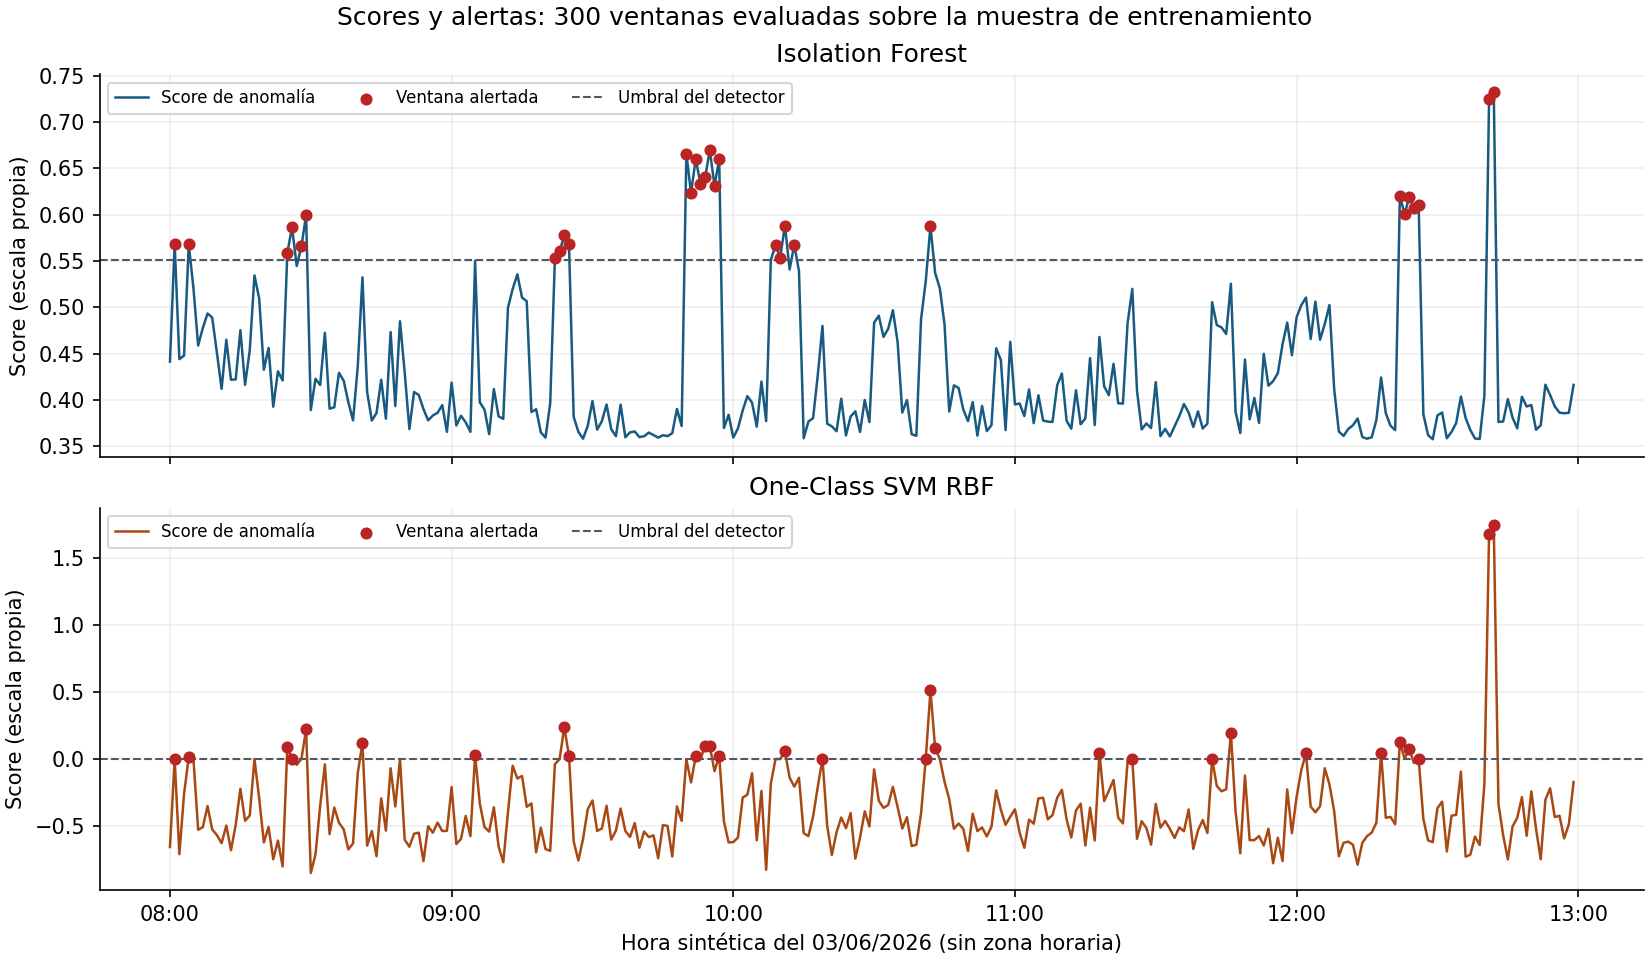

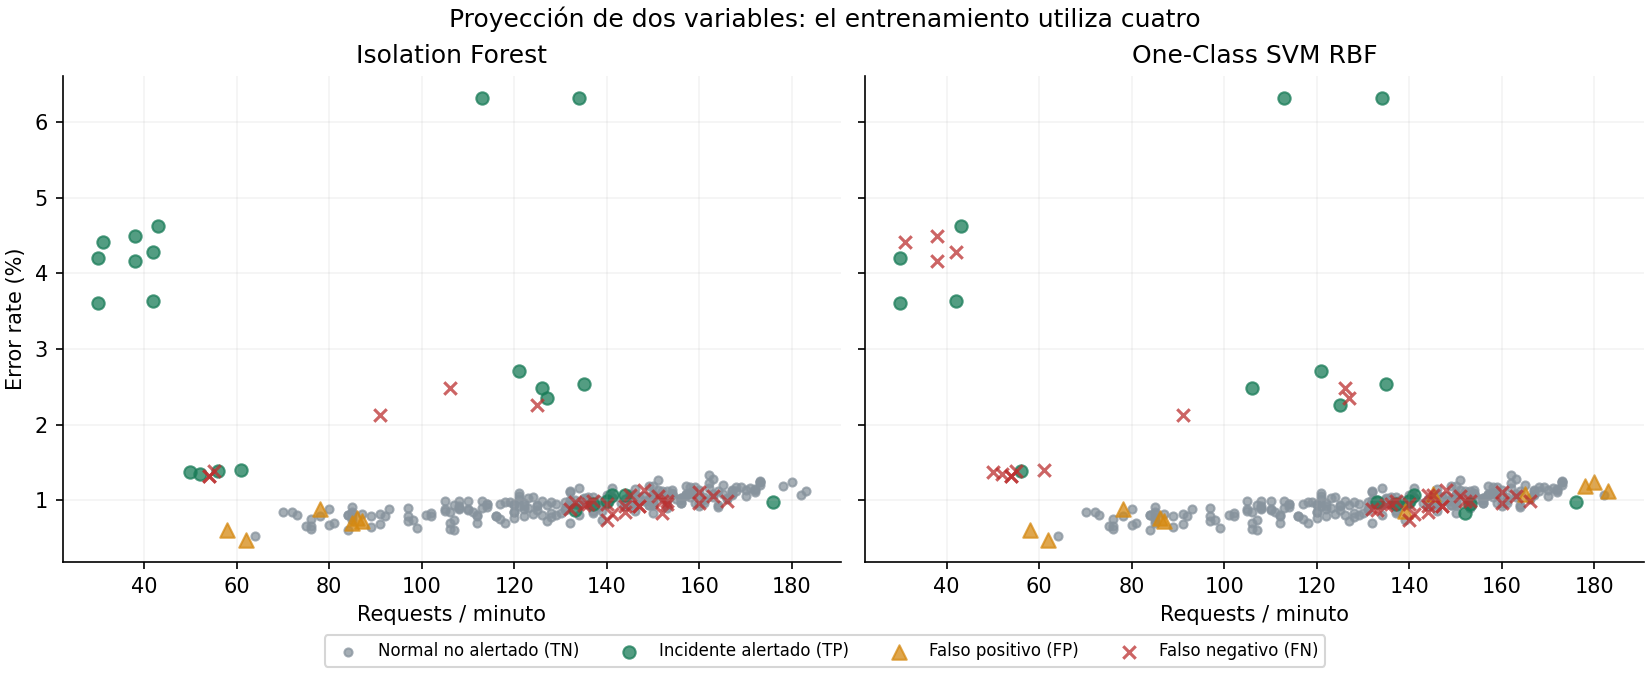

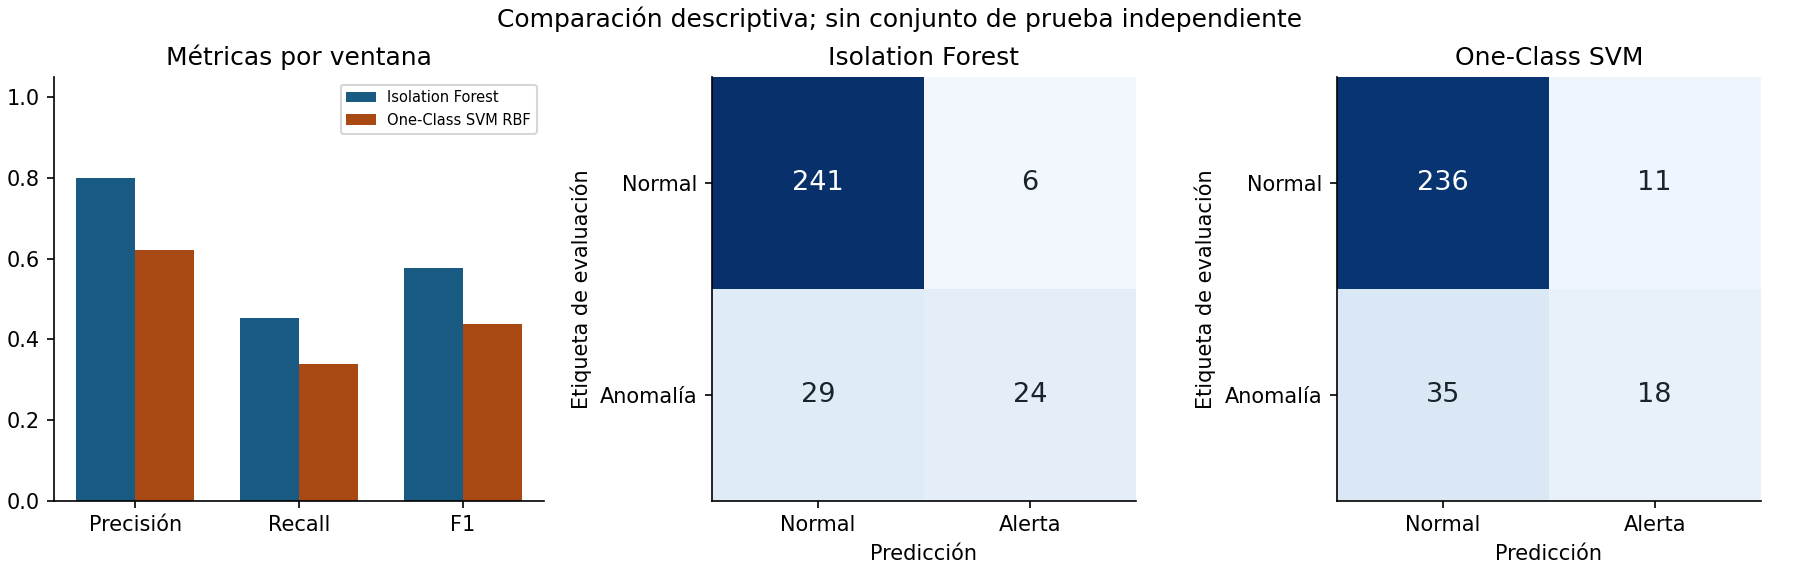

In [5]:
plot_dir = ROOT / ".runtime/ml-notebook-plots"
plot_dir.mkdir(parents=True, exist_ok=True)
make_plots(data, predictions, metrics, models, plot_dir)
for filename in ("scores_timeline.png", "projection.png", "comparison.png"):
    display(Image(filename=str(plot_dir / filename)))

## Errores con contexto operativo

Se muestran ejemplos de un falso positivo y un falso negativo de cada modelo, con su vector completo. La tabla por tipo permite revisar todos los casos, sin seleccionar solo ejemplos favorables. Las actividades legítimas raras pueden generar alertas; las tendencias lentas pueden pasar inadvertidas al puntuar minutos de forma independiente.

In [6]:
examples = []
for key in ("if", "ocsvm"):
    for label, mask in (("FP", ~data.is_anomaly & predictions[f"flag_{key}"]),
                        ("FN", data.is_anomaly & ~predictions[f"flag_{key}"])):
        selected = data.loc[mask, ["timestamp", "kind", *FEATURES]].head(1).copy()
        selected["model"] = key
        selected["case"] = label
        selected["score"] = predictions.loc[selected.index, f"score_{key}"]
        examples.append(selected)
import pandas as pd
display(pd.concat(examples).round(6))

,timestamp,kind,requests,error_rate,latency_ms,cpu_pct,model,case,score
1,2026-06-03 08:01:00,normal,62.0,0.004756,77.885997,26.950213,if,FP,0.568605
18,2026-06-03 08:18:00,spike_error,91.0,0.021210,84.029151,36.923715,if,FN,0.534351
1,2026-06-03 08:01:00,normal,62.0,0.004756,77.885997,26.950213,ocsvm,FP,0.000501
18,2026-06-03 08:18:00,spike_error,91.0,0.021210,84.029151,36.923715,ocsvm,FN,-0.000276


In [7]:
if_row, svm_row = metrics.iloc[0], metrics.iloc[1]
display(Markdown(
    f"En esta muestra, IF alerta **{int(if_row.alerts)}** ventanas: TP={int(if_row.tp)}, "
    f"FP={int(if_row.fp)}, FN={int(if_row.fn)}, F1={if_row.f1:.3f}. "
    f"OCSVM alerta **{int(svm_row.alerts)}**: TP={int(svm_row.tp)}, "
    f"FP={int(svm_row.fp)}, FN={int(svm_row.fn)}, F1={svm_row.f1:.3f}. "
    "Esta diferencia no demuestra que un modelo sea superior en producción."
))

En esta muestra, IF alerta **30** ventanas: TP=24, FP=6, FN=29, F1=0.578. OCSVM alerta **29**: TP=18, FP=11, FN=35, F1=0.439. Esta diferencia no demuestra que un modelo sea superior en producción.

## Conclusiones y siguientes validaciones

- Hay 53 minutos etiquetados anómalos (~17,7%) frente a políticas de alerta cercanas al 10%; el presupuesto y la geometría condicionan qué se omite.
- Revisar `batch`, `pico_carga`, `combo_sutil` y `degradacion` en la tabla; una alerta estadística requiere contexto operativo antes de iniciar mitigación.
- El dataset contiene autocorrelación y tendencias. Estos modelos no usan timestamp ni una secuencia temporal como feature; no se calcula MTTD ni se cuenta una alerta por incidente.
- El protocolo docente es deliberadamente sobre una muestra contaminada completa. Para uso operativo habrá que acordar un protocolo temporal y validar fuera de muestra; aquí no se cambiaron silenciosamente las reglas ni se tunearon con las etiquetas.
- Confirmar Q03 con el docente antes de declarar R05 aceptado. No se da por cerrado ese punto por tener un notebook ejecutado.

Los [resultados completos versionados](../docs/evidence/issue-14-20261112/results/RESULTS.md) incluyen scores y flags de las 300 ventanas, todos los FP/FN, parámetros, versiones y hashes. La [guía ML](README.md) permite reproducir la ejecución por CLI y este cuaderno.